In [7]:
import pandas as pd
df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()

(1941, 35)


,id,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,1,42,50,270900,270944,267,17,44,24220,76,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,2,645,651,2538079,2538108,108,10,30,11397,84,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,3,829,835,1553913,1553931,71,8,19,7972,99,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,4,853,860,369370,369415,176,13,45,18996,99,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,5,1289,1306,498078,498335,2409,60,260,246930,37,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [8]:
print(df.dtypes.value_counts())
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.columns.tolist()

int64      22
float64    13
Name: count, dtype: int64
Missing values: 0
Duplicates: 0


['id',
 'X_Minimum',
 'X_Maximum',
 'Y_Minimum',
 'Y_Maximum',
 'Pixels_Areas',
 'X_Perimeter',
 'Y_Perimeter',
 'Sum_of_Luminosity',
 'Minimum_of_Luminosity',
 'Maximum_of_Luminosity',
 'Length_of_Conveyer',
 'TypeOfSteel_A300',
 'TypeOfSteel_A400',
 'Steel_Plate_Thickness',
 'Edges_Index',
 'Empty_Index',
 'Square_Index',
 'Outside_X_Index',
 'Edges_X_Index',
 'Edges_Y_Index',
 'Outside_Global_Index',
 'LogOfAreas',
 'Log_X_Index',
 'Log_Y_Index',
 'Orientation_Index',
 'Luminosity_Index',
 'SigmoidOfAreas',
 'Pastry',
 'Z_Scratch',
 'K_Scatch',
 'Stains',
 'Dirtiness',
 'Bumps',
 'Other_Faults']

In [9]:
fault_cols = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
feature_cols = [c for c in df.columns if c not in fault_cols + ["id"]]

print(len(feature_cols), "features")
df[fault_cols].sum().sort_values(ascending=False)

27 features


Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
dtype: int64

In [10]:
df[feature_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,5.711360e+02,5.206907e+02,0.0000,51.0000,4.350000e+02,1.053000e+03,1.705000e+03
X_Maximum,1941.0,6.179645e+02,4.976274e+02,4.0000,192.0000,4.670000e+02,1.072000e+03,1.713000e+03
Y_Minimum,1941.0,1.650685e+06,1.774578e+06,6712.0000,471253.0000,1.204128e+06,2.183073e+06,1.298766e+07
Y_Maximum,1941.0,1.650739e+06,1.774590e+06,6724.0000,471281.0000,1.204136e+06,2.183084e+06,1.298769e+07
Pixels_Areas,1941.0,1.893878e+03,5.168460e+03,2.0000,84.0000,1.740000e+02,8.220000e+02,1.526550e+05
X_Perimeter,1941.0,1.118552e+02,3.012092e+02,2.0000,15.0000,2.600000e+01,8.400000e+01,1.044900e+04
Y_Perimeter,1941.0,8.296600e+01,4.264829e+02,1.0000,13.0000,2.500000e+01,8.300000e+01,1.815200e+04
Sum_of_Luminosity,1941.0,2.063121e+05,5.122936e+05,250.0000,9522.0000,1.920200e+04,8.301100e+04,1.159141e+07
Minimum_of_Luminosity,1941.0,8.454869e+01,3.213428e+01,0.0000,63.0000,9.000000e+01,1.060000e+02,2.030000e+02
Maximum_of_Luminosity,1941.0,1.301937e+02,1.869099e+01,37.0000,124.0000,1.270000e+02,1.400000e+02,2.530000e+02


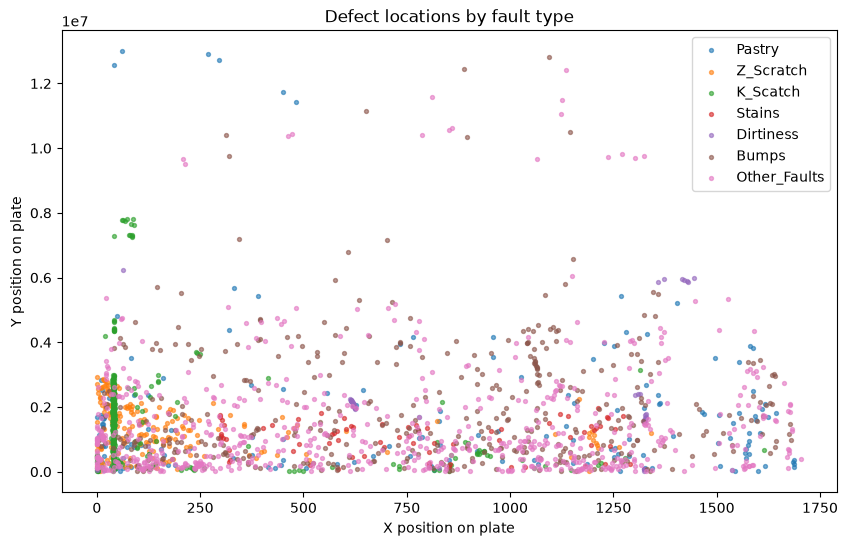

In [11]:
import matplotlib.pyplot as plt

df["fault_type"] = df[fault_cols].idxmax(axis=1)

plt.figure(figsize=(10, 6))
for f in fault_cols:
    sub = df[df["fault_type"] == f]
    plt.scatter(sub["X_Minimum"], sub["Y_Minimum"], s=8, label=f, alpha=0.6)
plt.legend()
plt.xlabel("X position on plate")
plt.ylabel("Y position on plate")
plt.title("Defect locations by fault type")
plt.show()

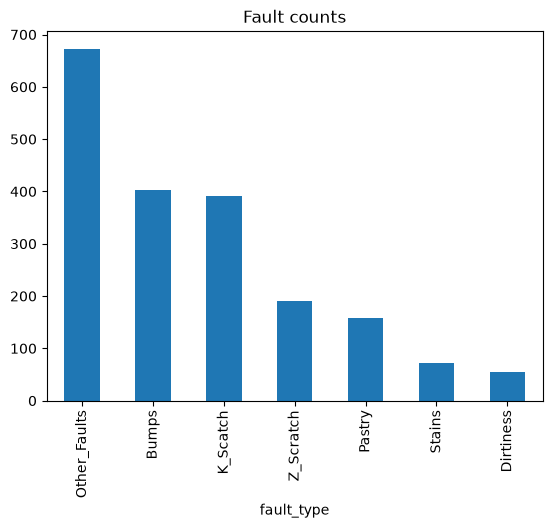

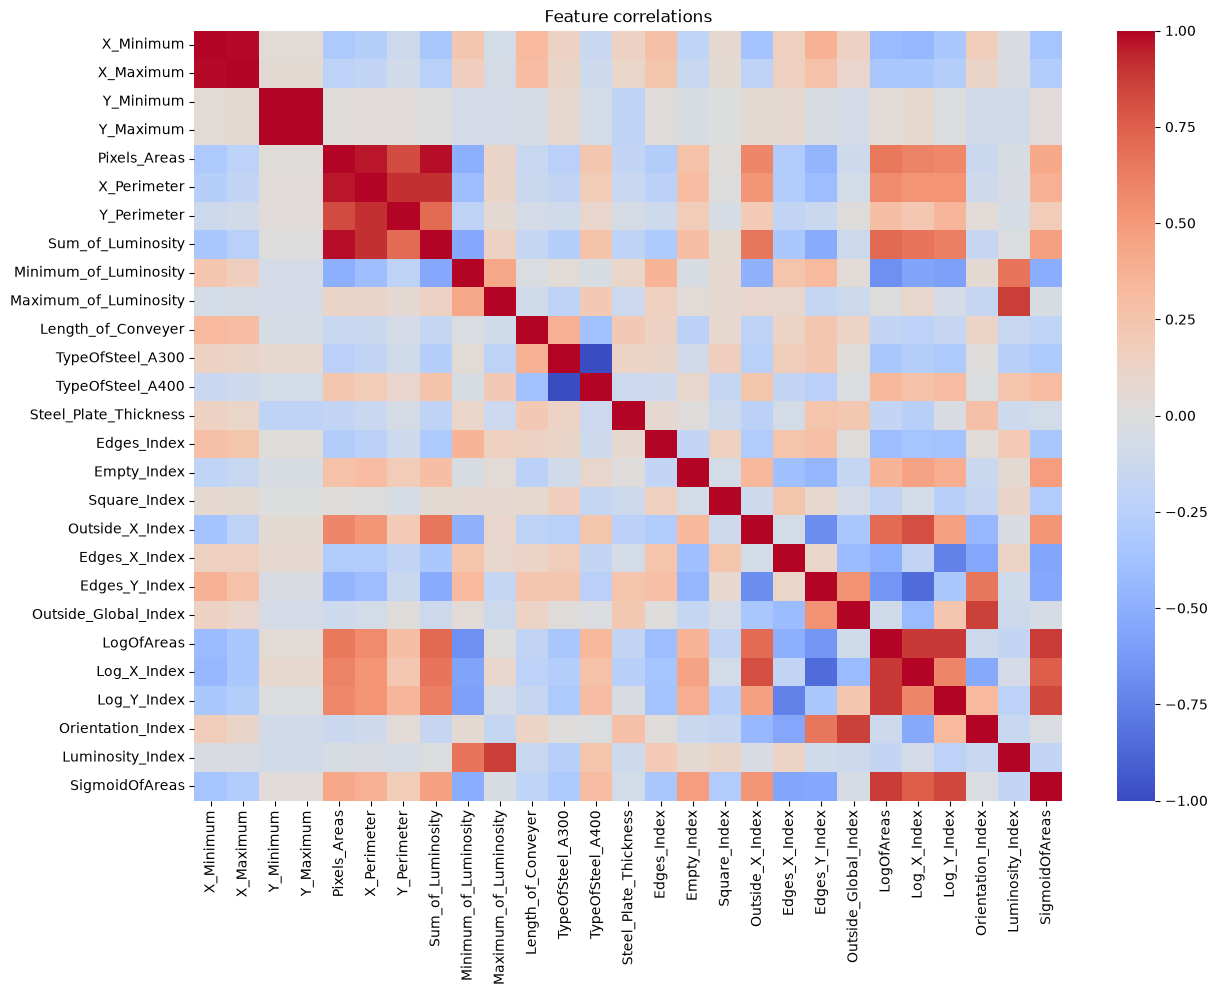

In [12]:
import seaborn as sns

df["fault_type"].value_counts().plot(kind="bar", title="Fault counts")
plt.show()

plt.figure(figsize=(14, 10))
sns.heatmap(df[feature_cols].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlations")
plt.show()

              precision    recall  f1-score   support

       Bumps       0.63      0.77      0.69        81
   Dirtiness       1.00      0.91      0.95        11
    K_Scatch       0.99      0.94      0.96        78
Other_Faults       0.77      0.64      0.70       135
      Pastry       0.54      0.78      0.64        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.89      0.93        38

    accuracy                           0.78       389
   macro avg       0.83      0.83      0.82       389
weighted avg       0.80      0.78      0.78       389



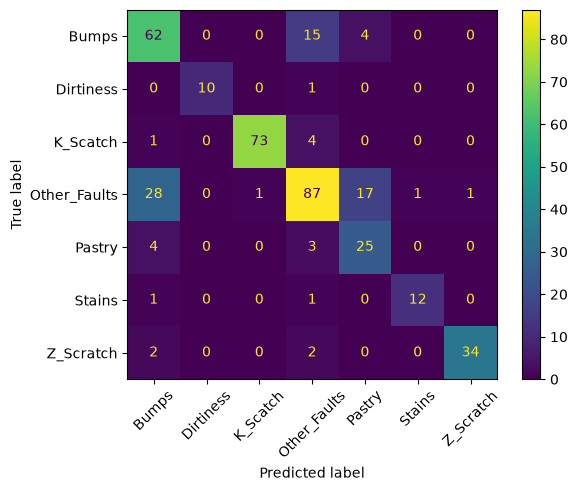

In [13]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df["fault_type"] = df[fault_cols].idxmax(axis=1)
feature_cols = [c for c in df.columns if c not in fault_cols + ["id", "fault_type"]]

Xc = df[feature_cols].drop(columns=["TypeOfSteel_A400"])
yc = df["fault_type"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=42)

clf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                             random_state=42, n_jobs=-1)
clf.fit(Xc_tr, yc_tr)
pred = clf.predict(Xc_te)

print(classification_report(yc_te, pred))
ConfusionMatrixDisplay.from_predictions(yc_te, pred, xticks_rotation=45)
plt.show()

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error

leaky = ["Pixels_Areas", "LogOfAreas", "SigmoidOfAreas", "X_Perimeter",
         "Y_Perimeter", "Sum_of_Luminosity", "Log_X_Index", "Log_Y_Index",
         "X_Maximum", "Y_Maximum", "TypeOfSteel_A400"]

y = np.log1p(df["Pixels_Areas"])
X = df[feature_cols].drop(columns=leaky)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

for name, model in [("Mean baseline", DummyRegressor()),
                    ("Random Forest", RandomForestRegressor(
                        n_estimators=300, random_state=42, n_jobs=-1))]:
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    print(f"{name}: R2 = {r2_score(y_te, p):.3f}, MAE = {mean_absolute_error(y_te, p):.3f} (log units)")

Mean baseline: R2 = -0.000, MAE = 1.490 (log units)
Random Forest: R2 = 0.985, MAE = 0.149 (log units)


Outside_X_Index          0.781620
Edges_X_Index            0.098084
Orientation_Index        0.044509
Minimum_of_Luminosity    0.018862
Square_Index             0.014699
X_Minimum                0.008036
Outside_Global_Index     0.005702
Empty_Index              0.005359
dtype: float64


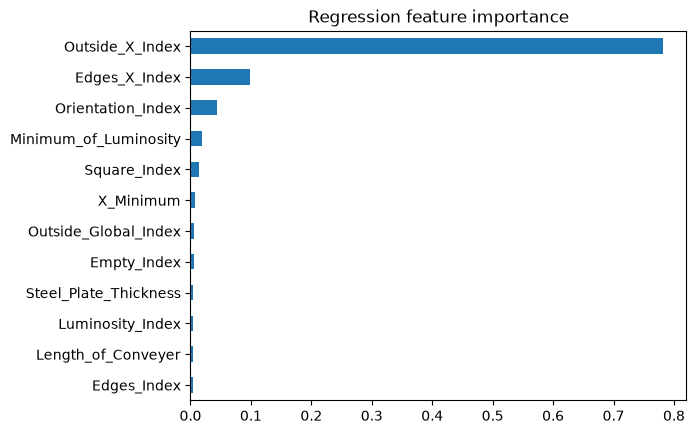

In [16]:
imp = (pd.Series(model.feature_importances_, index=X_tr.columns)
         .sort_values(ascending=False))
print(imp.head(8))
imp.head(12).iloc[::-1].plot(kind="barh", title="Regression feature importance")
plt.show()

In [17]:
top = imp.head(3).index.tolist()
print("Dropping:", top)
m = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
m.fit(X_tr.drop(columns=top), y_tr)
p = m.predict(X_te.drop(columns=top))
print(f"R2 = {r2_score(y_te, p):.3f}, MAE = {mean_absolute_error(y_te, p):.3f}")

Dropping: ['Outside_X_Index', 'Edges_X_Index', 'Orientation_Index']
R2 = 0.881, MAE = 0.432


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

yc_enc = LabelEncoder().fit_transform(yc)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                             random_state=42, n_jobs=-1),
}
for name, mdl in models.items():
    s = cross_val_score(mdl, Xc, yc_enc, cv=cv, scoring="f1_macro")
    print(f"{name}: macro-F1 = {s.mean():.3f} ± {s.std():.3f}")

Random Forest: macro-F1 = 0.807 ± 0.014
XGBoost: macro-F1 = 0.822 ± 0.020


In [19]:
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

strict = ["Minimum_of_Luminosity", "Maximum_of_Luminosity", "Luminosity_Index",
          "Steel_Plate_Thickness", "Length_of_Conveyer", "TypeOfSteel_A300",
          "X_Minimum", "Y_Minimum"]

Xs = df[strict]
kf = KFold(5, shuffle=True, random_state=42)

regs = {
    "Mean baseline": DummyRegressor(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4,
                            random_state=42, n_jobs=-1),
}
for name, mdl in regs.items():
    r2 = cross_val_score(mdl, Xs, y, cv=kf, scoring="r2")
    mae = -cross_val_score(mdl, Xs, y, cv=kf, scoring="neg_mean_absolute_error")
    print(f"{name}: R2 = {r2.mean():.3f} ± {r2.std():.3f}, MAE = {mae.mean():.3f}")

Mean baseline: R2 = -0.001 ± 0.001, MAE = 1.469
Random Forest: R2 = 0.803 ± 0.013, MAE = 0.553
XGBoost: R2 = 0.795 ± 0.018, MAE = 0.578


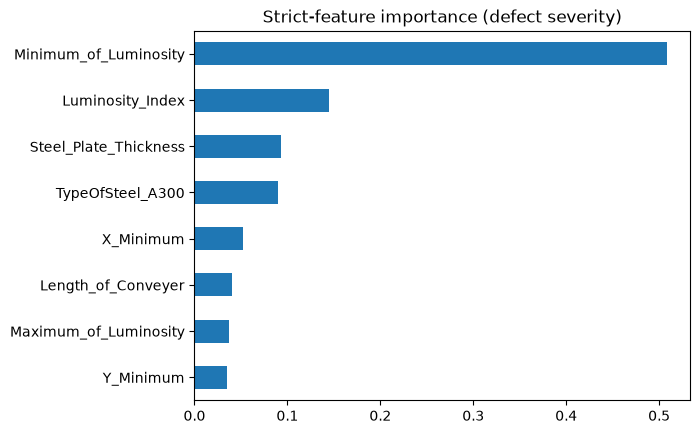

In [20]:
final = XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4,
                     random_state=42, n_jobs=-1).fit(Xs, y)
pd.Series(final.feature_importances_, index=strict).sort_values().plot(
    kind="barh", title="Strict-feature importance (defect severity)")
plt.show()

In [21]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight

params = {"n_estimators": [200, 400, 600], "max_depth": [3, 4, 5, 6],
          "learning_rate": [0.02, 0.05, 0.1], "subsample": [0.7, 0.85, 1.0],
          "colsample_bytree": [0.6, 0.8, 1.0]}
search = RandomizedSearchCV(
    XGBClassifier(random_state=42, n_jobs=-1), params, n_iter=20,
    scoring="f1_macro", cv=cv, random_state=42, n_jobs=-1)
search.fit(Xc, yc_enc, sample_weight=compute_sample_weight("balanced", yc_enc))
print("Best macro-F1:", round(search.best_score_, 3))
print(search.best_params_)

Best macro-F1: 0.841
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


              precision    recall  f1-score   support

       Bumps       0.84      0.81      0.82        81
   Dirtiness       1.00      0.73      0.84        11
    K_Scatch       0.99      0.94      0.96        78
Other_Faults       0.85      0.81      0.83       135
      Pastry       0.70      0.94      0.80        32
      Stains       0.82      1.00      0.90        14
   Z_Scratch       0.97      1.00      0.99        38

    accuracy                           0.87       389
   macro avg       0.88      0.89      0.88       389
weighted avg       0.88      0.87      0.87       389



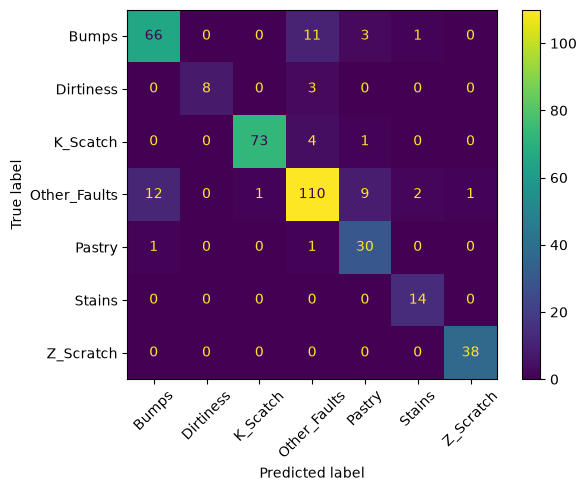

In [22]:
best = XGBClassifier(**search.best_params_, random_state=42, n_jobs=-1)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc_enc, test_size=0.2, stratify=yc_enc, random_state=7)

best.fit(Xc_tr, yc_tr, sample_weight=compute_sample_weight("balanced", yc_tr))
pred = best.predict(Xc_te)

le = LabelEncoder().fit(yc)
print(classification_report(yc_te, pred, target_names=le.classes_))
ConfusionMatrixDisplay.from_predictions(yc_te, pred,
    display_labels=le.classes_, xticks_rotation=45)
plt.show()

Held-out R2 = 0.820, MAE = 0.520


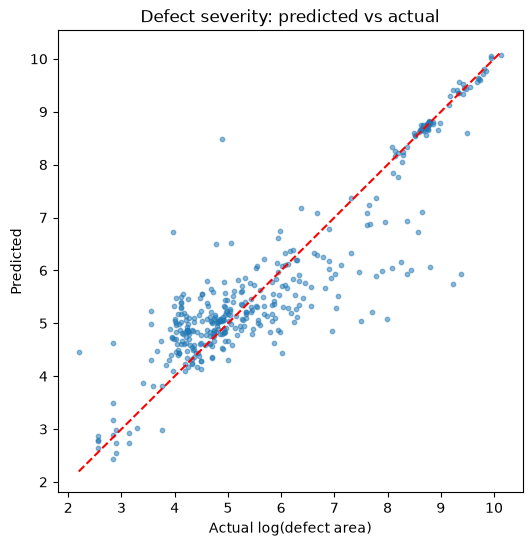

In [23]:
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, y, test_size=0.2, random_state=7)
reg = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xs_tr, ys_tr)
p = reg.predict(Xs_te)
print(f"Held-out R2 = {r2_score(ys_te, p):.3f}, MAE = {mean_absolute_error(ys_te, p):.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(ys_te, p, s=10, alpha=0.5)
lims = [ys_te.min(), ys_te.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual log(defect area)"); plt.ylabel("Predicted")
plt.title("Defect severity: predicted vs actual")
plt.show()

/Users/veerverma/Desktop/steel-defect-depth/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


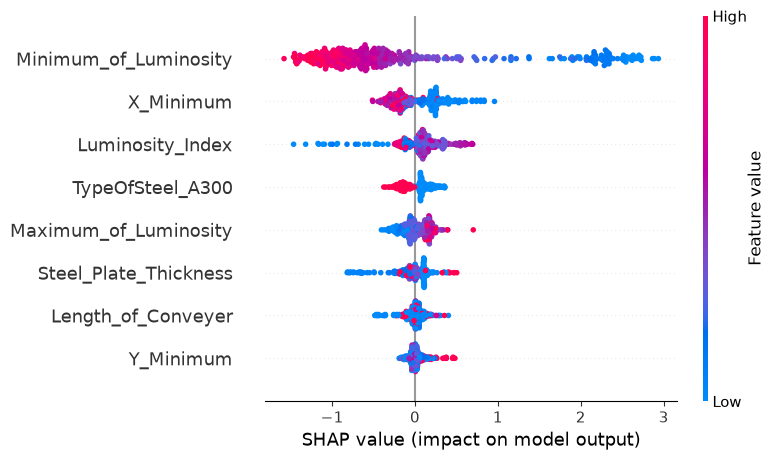

In [24]:
import shap
explainer = shap.TreeExplainer(reg)
sv = explainer.shap_values(Xs_te)
shap.summary_plot(sv, Xs_te)

In [25]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(best, "../models/fault_classifier.joblib")
joblib.dump(reg, "../models/severity_regressor.joblib")
joblib.dump(le, "../models/label_encoder.joblib")

['../models/label_encoder.joblib']

In [26]:
pip freeze > requirements.txt
printf "venv/\ndata/\n.ipynb_checkpoints/\n__pycache__/\n" > .gitignore
git init && git add . && git commit -m "Steel defect classification and severity model"

SyntaxError: invalid syntax (1545142963.py, line 1)

# Steel Defect Classification & Severity Prediction

Classify the fault type of steel plates and estimate defect severity from
inspection measurements. Python, scikit-learn, XGBoost, SHAP.

**Data:** Steel Plates Faults, 1,941 plates, 27 features, 7 fault types
(download from Kaggle/UCI and place `train.csv` in `data/`).

## Results
| Task | Model | Metric |
|---|---|---|
| Fault type (7 classes) | Tuned XGBoost | Macro-F1 0.84 (5-fold CV), 0.88 (held-out, n=389) |
| Defect severity (log area) | Random Forest | CV R² 0.80, MAE 0.55; held-out R² [X], MAE [Y] |

## Method
1. EDA: no missing values or duplicates; classes imbalanced (55 to 673 plates).
   Defect locations cluster by fault type (see `images/`).
2. Classification: class-weighted XGBoost, randomized hyperparameter search.
3. **Leakage audit:** an initial severity model scored R² 0.985, but one
   geometry feature (Outside_X_Index) held 78% of the importance. Shape-derived
   features were removed and the model was rebuilt on inspection-style features only
   (luminosity, steel type, thickness, conveyer length, position). R² fell to 0.80,
   which is the figure reported.
4. Interpretation with SHAP: darker defects and plates near the edge are
   predicted larger.

## Limitations
- The dataset has no physical depth measurement. The target is defect **area**,
  used as a severity proxy.
- Large defects are underpredicted (see predicted-vs-actual plot).
- Dirtiness and Stains have very few samples, so their per-class scores are noisy.
- Other_Faults is a catch-all label, which limits classification accuracy.